## NetSentinel — AI-Powered Network Intrusion Detection.

### CICIDS Dataset Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
ds = pd.read_csv("../combinenew.csv")
ds.sample(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
1460759,80,116003502.0,16.0,14.0,508.0,1956.0,424.0,0.0,31.75,104.610707,...,20.0,50616.0,38563.28247,166880.0,38660.0,10000000.0,29444.41808,10100000.0,10000000.0,BENIGN
2053349,80,28538.0,1.0,1.0,0.0,0.0,0.0,0.0,0.00,0.000000,...,32.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,BENIGN
1353491,51576,3.0,2.0,0.0,247.0,0.0,216.0,31.0,123.50,130.814754,...,32.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,BENIGN
1729852,53,74327.0,1.0,1.0,44.0,176.0,44.0,44.0,44.00,0.000000,...,32.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,BENIGN
980338,443,63.0,3.0,0.0,18.0,0.0,6.0,6.0,6.00,0.000000,...,20.0,0.0,0.00000,0.0,0.0,0.0,0.00000,0.0,0.0,BENIGN


In [3]:
ds.columns = ds.columns.str.strip()
ds.columns = [x.replace(' ','_') for x in ds.columns]

In [4]:
# To remove all the columns that have majority of 0 or 1 only.
unnecessary_columns = [col for col in ds.columns if ds[col].value_counts(normalize=True).sort_values(ascending=False).iloc[0] > 0.95]
ds.drop(columns=unnecessary_columns, inplace=True)

In [5]:
ds['Port_Type'] = ds['Destination_Port'].apply(lambda x: "System Port" if x in range(0,1024)
                             else ("Registered Port" if x in range(1024,49152)
                                   else "Dynamic Port"))

In [6]:
ds['Duration_Category'] = pd.qcut(ds['Flow_Duration'], q=3, labels=['Short', 'Medium', 'Long'])

In [7]:
print(f"Short Duration Range : {ds[ds['Duration_Category']=='Short']['Flow_Duration'].min()} - {ds[ds['Duration_Category']=='Short']['Flow_Duration'].max()}")
print(f"Medium Duration Range : {ds[ds['Duration_Category']=='Medium']['Flow_Duration'].min()} - {ds[ds['Duration_Category']=='Medium']['Flow_Duration'].max()}")
print(f"Long Duration Range : {ds[ds['Duration_Category']=='Long']['Flow_Duration'].min()} - {ds[ds['Duration_Category']=='Long']['Flow_Duration'].max()}")

Short Duration Range : -13.0 - 221.0
Medium Duration Range : 222.0 - 182674.0
Long Duration Range : 182676.0 - 119999998.0


In [8]:
ds[['Destination_Port','Port_Type','Duration_Category','Flow_Duration']].sample(5)

,Destination_Port,Port_Type,Duration_Category,Flow_Duration
226499,53,System Port,Medium,33003.0
49268,80,System Port,Medium,57393.0
710585,53,System Port,Medium,61076.0
1779305,53238,Dynamic Port,Short,9.0
2153130,53,System Port,Medium,60160.0


### <b>Part A: Dataset Understanding</b>

1. <u>Identify the domain of the dataset.</u>

- Network Intrusion Detection (CICIDS2017)
- The dataset contains various features related to network traffic, such as packet lengths, flow durations, and other characteristics.
- We need to analyze network behavior and identify potential anomalies or patterns in the traffic. 
- It is Network Intrusion Detection system, which contains both normal as well as abnormal traffics.

2. <u>List all numerical and categorical attributes.</u>

- **Categorical Columns** : Originally we had only single categorical column - Label. We performed feature engineering on some columns and converted them to categorical - providing meaningful insights.
    
    - __Label__ : Target Variable (e.g. Dos, Botnet, Benign etc.)
    - __Port_Category__ : Feature Engineered - Converted ports number into System, Registered or Dynamic ports
    - __Flow_Duration__ : Feature Engineered - Converted duration of flow into Short, Medium, Long
    - __Extras__ : Some columns like Flag_Counts (FIN, SYN, RST) are generally operated as categorical i.e. 0 or 1

- **Numerical Columns** : There are many numerical columns in dataset, each representing packets, data, length and many more.
    
    - __Forward Packet__ : All packets sent by user to server (e.g. Accessing a website, requesting a video etc.)
    - __Backword Packet__ : Responses generated by server for client (e.g. Requested webpage/video/content)
    - __Extras__ : Many more numerical columns exists holding some value like length of packet, sending time, total duration etc.

3. <u>Explain why normalization is required for the selected dataset.</u>

- **Binary Columns** : Some columns that describes flag counts are recorded as 0 or 1, so no need to normalize them.
- **Packets Length** : Total Length of Forward/Backward Packets ranges from 0 to 1 Lakhs/Millions, such are needed to normalize to avoid extreme fluctuations.
- **Speed** : Lakhs/Millions of  packets to be sent (either Forward or Backward) in a second, needed to normalize them too.

- Such columns, if prevented to normalize -> lead to drastic performance when trained on distance based models such as KNN.

### <b>Part B: Data Preparation</b>


#### 1. Load and inspect the dataset.

In [9]:
ds.sample(5)

,Destination_Port,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Total_Length_of_Fwd_Packets,Total_Length_of_Bwd_Packets,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,...,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,Label,Port_Type,Duration_Category
2066428,53,180.0,2.0,2.0,90.0,122.0,45.0,45.0,45.000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,System Port,Short
2264208,80,85294901.0,8.0,7.0,355.0,11595.0,355.0,0.0,44.375,125.511454,...,0.0,1074.0,1074.0,85100000.0,0.0,85100000.0,85100000.0,DoS Hulk,System Port,Long
2730839,53,54015.0,4.0,2.0,144.0,370.0,36.0,36.0,36.000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,System Port,Medium
2499595,53,226.0,2.0,2.0,70.0,262.0,35.0,35.0,35.000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,System Port,Medium
398008,3920,52.0,1.0,1.0,0.0,6.0,0.0,0.0,0.000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,PortScan,Registered Port,Short


In [10]:
ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 2830744 entries, 0 to 2830743
Data columns (total 66 columns):
 #   Column                       Dtype   
---  ------                       -----   
 0   Destination_Port             object  
 1   Flow_Duration                float64 
 2   Total_Fwd_Packets            float64 
 3   Total_Backward_Packets       float64 
 4   Total_Length_of_Fwd_Packets  float64 
 5   Total_Length_of_Bwd_Packets  float64 
 6   Fwd_Packet_Length_Max        float64 
 7   Fwd_Packet_Length_Min        float64 
 8   Fwd_Packet_Length_Mean       float64 
 9   Fwd_Packet_Length_Std        float64 
 10  Bwd_Packet_Length_Max        float64 
 11  Bwd_Packet_Length_Min        float64 
 12  Bwd_Packet_Length_Mean       float64 
 13  Bwd_Packet_Length_Std        float64 
 14  Flow_Bytes/s                 float64 
 15  Flow_Packets/s               float64 
 16  Flow_IAT_Mean                float64 
 17  Flow_IAT_Std                 float64 
 18  Flow_IAT_Max                 floa

#### 2. Handle missing values (if any).

In [11]:
ds.isnull().sum().sort_values(ascending=False)

Flow_Bytes/s                   1359
Flow_Duration                     1
Min_Packet_Length                 1
Total_Fwd_Packets                 1
Total_Length_of_Fwd_Packets       1
                               ... 
Idle_Max                          1
Duration_Category                 1
Label                             1
Destination_Port                  0
Port_Type                         0
Length: 66, dtype: int64

In [12]:
ds.dropna(inplace=True)
print("Columns Dropped.")

Columns Dropped.


#### 3. Remove duplicate records (if any).


In [13]:
print(f"Duplicate Records : {ds.duplicated().sum()} \nShape : {ds.shape}")

Duplicate Records : 329402 
Shape : (2829385, 66)


In [14]:
ds.drop_duplicates(inplace=True)
print(f"Duplicate Records : {ds.duplicated().sum()}")

Duplicate Records : 0


### <b>Part C: Normalization Techniques</b>

In [15]:
numeric_cols = ds.select_dtypes(include=np.number)
cols_to_exclude = [col for col in numeric_cols if len(numeric_cols[col].value_counts()) <= 3]
numeric_cols = numeric_cols.drop(columns=cols_to_exclude)

In [16]:
for col in numeric_cols.columns:
    numeric_cols[col] = np.sign(numeric_cols[col]) * np.log1p(np.abs(numeric_cols[col]))

In [17]:
numeric_cols.describe()

,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Total_Length_of_Fwd_Packets,Total_Length_of_Bwd_Packets,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Max,...,act_data_pkt_fwd,min_seg_size_forward,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min
count,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,...,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06,2.499983e+06
mean,1.071521e+01,1.454703e+00,1.242473e+00,4.067871e+00,4.677266e+00,3.611646e+00,1.652769e+00,3.057515e+00,1.694954e+00,4.175313e+00,...,8.457527e-01,3.261185e+00,2.296068e+00,9.702820e-01,2.393532e+00,2.186012e+00,3.856748e+00,1.100671e+00,3.866534e+00,3.830112e+00
std,5.285840e+00,7.990822e-01,9.207282e-01,2.282344e+00,3.313350e+00,2.080260e+00,1.735812e+00,1.593056e+00,2.306067e+00,2.904326e+00,...,8.441141e-01,2.640431e-01,4.520712e+00,3.298202e+00,4.739472e+00,4.297440e+00,7.138423e+00,3.590309e+00,7.156985e+00,7.091233e+00
min,-2.639057e+00,6.931472e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,-2.010127e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.361292e+00,1.098612e+00,6.931472e-01,2.564949e+00,1.945910e+00,1.945910e+00,0.000000e+00,1.945910e+00,0.000000e+00,1.945910e+00,...,0.000000e+00,3.044522e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,1.085192e+01,1.098612e+00,1.098612e+00,4.204693e+00,5.056246e+00,3.713572e+00,1.098612e+00,3.613617e+00,0.000000e+00,4.595120e+00,...,6.931472e-01,3.044522e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,1.549896e+01,1.945910e+00,1.791759e+00,5.820083e+00,6.996681e+00,5.332719e+00,3.637586e+00,3.970292e+00,4.333673e+00,6.680855e+00,...,1.386294e+00,3.496508e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,1.860300e+01,1.230029e+01,1.258425e+01,1.637274e+01,2.030084e+01,1.011945e+01,7.751905e+00,8.689777e+00,8.871589e+00,9.879758e+00,...,1.227166e+01,4.934474e+00,1.851599e+01,1.812227e+01,1.851599e+01,1.851599e+01,1.860300e+01,1.815802e+01,1.860300e+01,1.860300e+01


In [18]:
numeric_cols.replace([np.inf, -np.inf], np.nan, inplace=True)
numeric_cols.dropna(inplace=True)

#### 1. Min-Max Normalization

In [19]:
from sklearn.preprocessing import MinMaxScaler

minmax_scaler = MinMaxScaler()
minmax_data = minmax_scaler.fit_transform(numeric_cols)
minmax_data = pd.DataFrame(minmax_data, columns=numeric_cols.columns)
minmax_data.sample(3)

,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Total_Length_of_Fwd_Packets,Total_Length_of_Bwd_Packets,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Max,...,act_data_pkt_fwd,min_seg_size_forward,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min
542197,0.899581,0.220980,0.233978,0.545027,0.383579,0.793562,0.0,0.656853,0.740055,0.563224,...,0.258975,0.924510,0.659042,0.000000,0.659042,0.659042,0.884511,0.000000,0.884511,0.884511
709955,0.998462,0.220980,0.255786,0.347757,0.476225,0.562653,0.0,0.293743,0.461887,0.803289,...,0.056484,0.942563,0.577846,0.570553,0.639023,0.564761,0.867461,0.574745,0.867516,0.866917
776895,0.839486,0.138659,0.182974,0.449456,0.430824,0.698726,0.0,0.594571,0.671142,0.737556,...,0.179049,0.924510,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


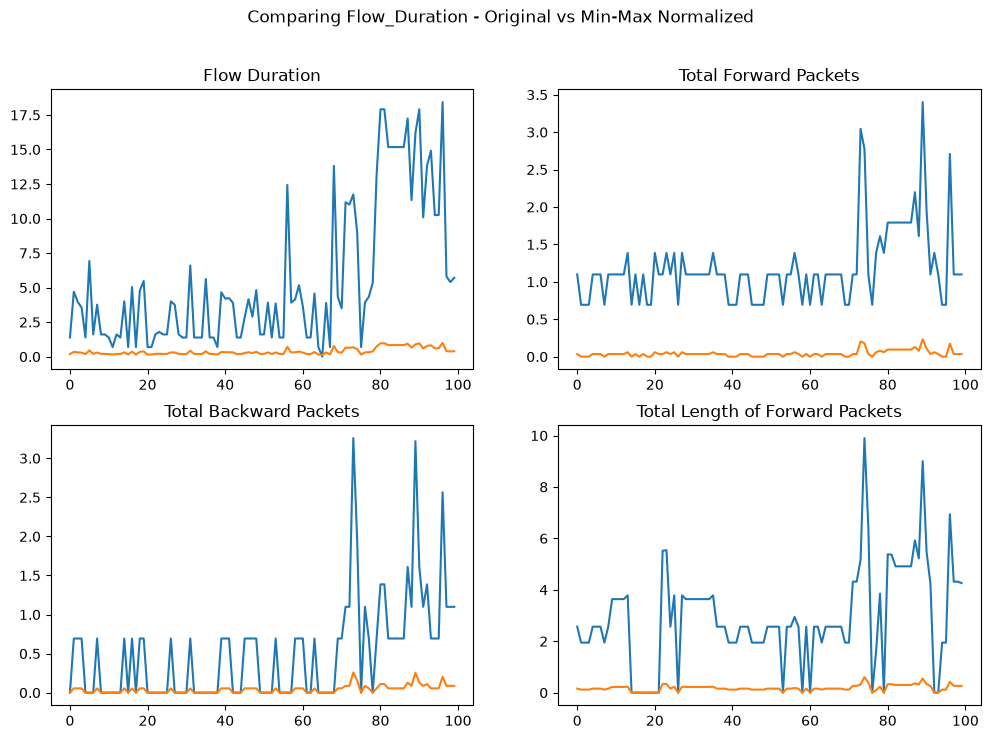

In [20]:
# Comparing 'Flow Duration' column before applying normalization and after applying normalization.

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].plot(numeric_cols["Flow_Duration"].head(100).values,label='Original')
axes[0,0].plot(minmax_data["Flow_Duration"].head(100).values, label='Min-Max Normalized')
axes[0,0].set_title("Flow Duration")

axes[0,1].plot(numeric_cols["Total_Fwd_Packets"].head(100).values,label='Original')
axes[0,1].plot(minmax_data["Total_Fwd_Packets"].head(100).values, label='Min-Max Normalized')
axes[0,1].set_title("Total Forward Packets")

axes[1,0].plot(numeric_cols["Total_Backward_Packets"].head(100).values,label='Original')
axes[1,0].plot(minmax_data["Total_Backward_Packets"].head(100).values, label='Min-Max Normalized')
axes[1,0].set_title("Total Backward Packets")

axes[1,1].plot(numeric_cols["Total_Length_of_Fwd_Packets"].head(100).values,label='Original')
axes[1,1].plot(minmax_data["Total_Length_of_Fwd_Packets"].head(100).values, label='Min-Max Normalized')
axes[1,1].set_title("Total Length of Forward Packets")

plt.suptitle("Comparing Flow_Duration - Original vs Min-Max Normalized")
plt.show()

#### 2. Z-Score Normalization (Standardization)

In [21]:
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()
standard_data = standard_scaler.fit_transform(numeric_cols)
standard_data = pd.DataFrame(standard_data, columns=numeric_cols.columns)
standard_data.sample(3)

,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Total_Length_of_Fwd_Packets,Total_Length_of_Bwd_Packets,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Max,...,act_data_pkt_fwd,min_seg_size_forward,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min
1923167,-0.118781,-0.445928,-0.156688,0.018445,0.271856,-0.085764,1.025926,0.235959,-0.735138,0.245684,...,-0.181127,-0.820685,-0.508052,-0.294261,-0.505171,-0.50883,-0.540446,-0.306647,-0.540412,-0.540285
496152,-1.724911,-0.445928,-1.349888,0.687681,-1.412313,0.963466,0.168803,1.186763,1.541051,-1.438285,...,-0.181127,-0.820685,-0.508052,-0.294261,-0.505171,-0.50883,-0.540446,-0.306647,-0.540412,-0.540285
1177038,-1.064087,-0.445928,-1.349888,-1.782657,-1.412313,-1.736427,-0.952029,-1.919512,-0.735138,-1.438285,...,-1.002222,0.890990,-0.508052,-0.294261,-0.505171,-0.50883,-0.540446,-0.306647,-0.540412,-0.540285


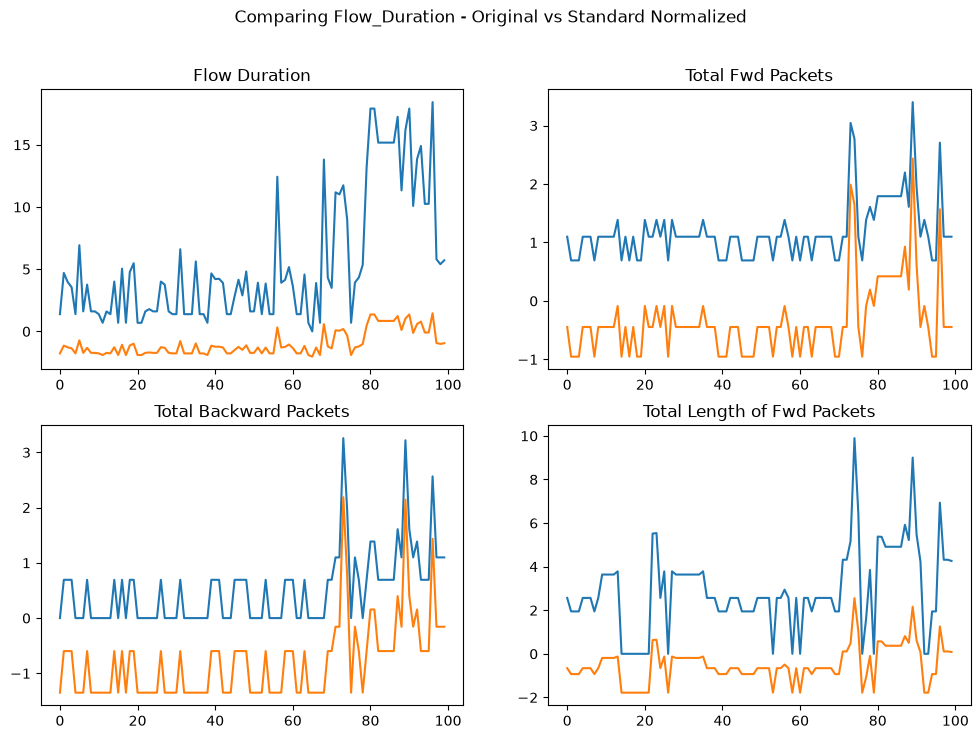

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].plot(numeric_cols["Flow_Duration"].head(100).values, label='Original')
axes[0,0].plot(standard_data["Flow_Duration"].head(100).values, label='Z-Score Standardized')
axes[0,0].set_title("Flow Duration")

axes[0,1].plot(numeric_cols["Total_Fwd_Packets"].head(100).values, label='Original')
axes[0,1].plot(standard_data["Total_Fwd_Packets"].head(100).values, label='Z-Score Standardized')
axes[0,1].set_title("Total Fwd Packets")

axes[1,0].plot(numeric_cols["Total_Backward_Packets"].head(100).values, label='Original')
axes[1,0].plot(standard_data["Total_Backward_Packets"].head(100).values, label='Z-Score Standardized')
axes[1,0].set_title("Total Backward Packets")

axes[1,1].plot(numeric_cols["Total_Length_of_Fwd_Packets"].head(100).values, label='Original')
axes[1,1].plot(standard_data["Total_Length_of_Fwd_Packets"].head(100).values, label='Z-Score Standardized')
axes[1,1].set_title("Total Length of Fwd Packets")

plt.suptitle("Comparing Flow_Duration - Original vs Standard Normalized")
plt.show()

### <b>Part D: Analysis</b>

#### 1. Compare the outputs obtained from different normalization techniques.

- After applying both normalization techniques, it was observed that both techniques successfully reduced the effect of large numerical values present in the dataset, but in a different way.
- <i>Min-Max Normalization</i> scaled values between 0 and 1. This made the dataset easier to understand but extreme smaller values came nearly to 0.
- Using <i>Standardization</i>, values were distributed around zero and both positive and negative values were obtained.

#### 2. Identify which normalization method is most suitable for the selected domain and justify your answer.

- For my selected domain of Cybersecurity , Z-Score Standardization is likely more suitable. Because values are scattered around 0 and lakhs, so Z-Score helps to handle such variations.
- In network traffic datasets, extreme values may contain important information related to attacks or unusual behaviour, like length of packet, duration flow or Forward/Backward Packets etc. many more.
- Hence, Z-Score Standardization was found to be more appropriate for this dataset, as it provides a balanced representation of network traffic features while reducing the impact of scale differences.

### OLAP Operations

In [23]:
olap_cube = pd.pivot_table(
    ds,
    values='Total_Fwd_Packets',
    index='Label',
    columns='Port_Type',
    aggfunc='mean'
)

display(olap_cube)

Port_Type,Dynamic Port,Registered Port,System Port
Label,,,
BENIGN,2.034994,2.593342,14.195975
Bot,1.000000,3.881096,NaN
DDoS,1.000000,1.000000,4.472710
DoS GoldenEye,7.245614,NaN,5.876715
DoS Hulk,NaN,NaN,6.363300
DoS Slowhttptest,NaN,NaN,5.982402
DoS slowloris,NaN,NaN,6.742990
FTP-Patator,NaN,NaN,6.679589
Heartbleed,NaN,NaN,2583.727273


In [24]:
dice = ds[
    (ds['Label'].isin(['DoS','DDoS'])) &
    (ds['Port_Type'] == 'System Port')
]

dice.head()

,Destination_Port,Flow_Duration,Total_Fwd_Packets,Total_Backward_Packets,Total_Length_of_Fwd_Packets,Total_Length_of_Bwd_Packets,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,...,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,Label,Port_Type,Duration_Category
18883,80,1293792.0,3.0,7.0,26.0,11607.0,20.0,0.0,8.666667,10.263203,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DDoS,System Port,Long
18884,80,4421382.0,4.0,0.0,24.0,0.0,6.0,6.0,6.000000,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DDoS,System Port,Long
18885,80,1083538.0,3.0,6.0,26.0,11601.0,20.0,0.0,8.666667,10.263203,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DDoS,System Port,Long
18886,80,80034360.0,8.0,4.0,56.0,11601.0,20.0,0.0,7.000000,5.656854,...,0.0,939.0,939.0,39300000.0,44200000.0,70600000.0,8072664.0,DDoS,System Port,Long
18887,80,642654.0,3.0,6.0,26.0,11607.0,20.0,0.0,8.666667,10.263203,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DDoS,System Port,Long


In [25]:
rollup = ds.groupby("Port_Type").agg({
    "Total_Fwd_Packets":"mean",
    "Total_Backward_Packets":"mean",
    "Flow_Bytes/s":"mean"
})

display(rollup)

,Total_Fwd_Packets,Total_Backward_Packets,Flow_Bytes/s
Port_Type,,,
Dynamic Port,2.020799,1.254169,inf
Registered Port,2.137814,1.374721,inf
System Port,12.690082,14.578581,inf


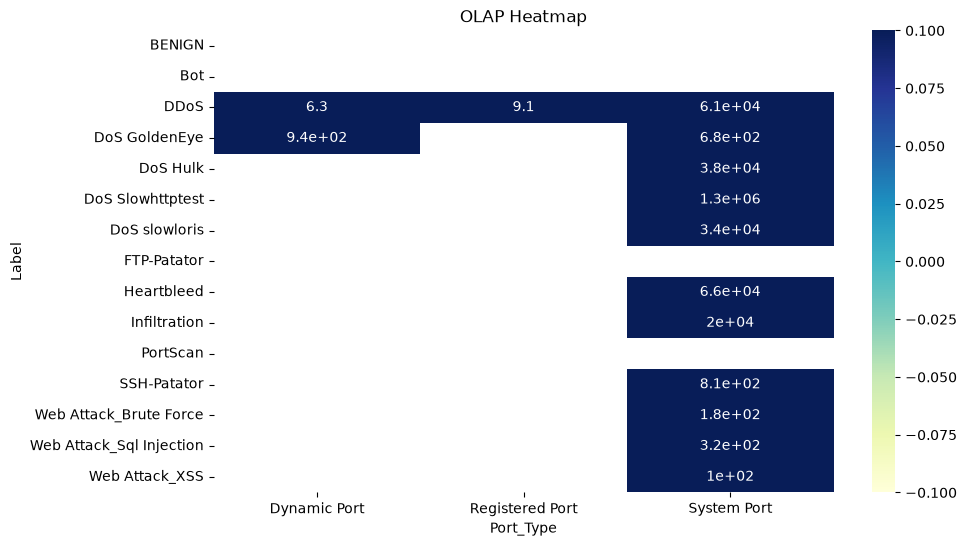

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

pivot = pd.pivot_table(
    ds,
    values="Flow_Bytes/s",
    index="Label",
    columns="Port_Type",
    aggfunc="mean"
)

plt.figure(figsize=(10,6))

sns.heatmap(
    pivot,
    annot=True,
    cmap="YlGnBu"
)

plt.title("OLAP Heatmap")
plt.show()

In [27]:
import plotly.express as px

fig = px.sunburst(
    ds,
    path=["Label","Port_Type"],
    values="Flow_Bytes/s",
    color="Flow_Bytes/s",
    color_continuous_scale="Viridis"
)

fig.show()

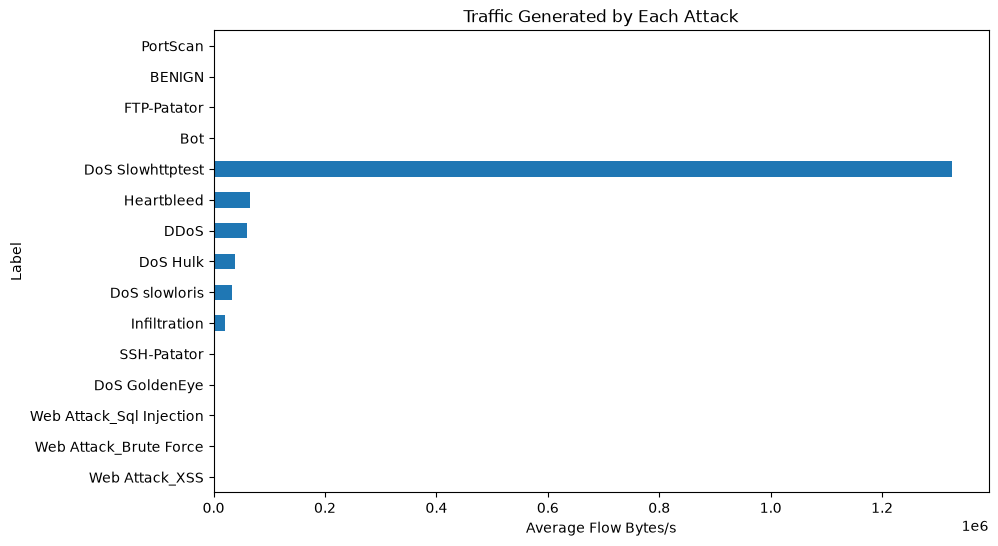

In [28]:
traffic = ds.groupby("Label")[
    "Flow_Bytes/s"
].mean().sort_values()

traffic.plot(
    kind="barh",
    figsize=(10,6)
)

plt.xlabel("Average Flow Bytes/s")
plt.title("Traffic Generated by Each Attack")
plt.show()

In [29]:
ds.columns

Index(['Destination_Port', 'Flow_Duration', 'Total_Fwd_Packets',
       'Total_Backward_Packets', 'Total_Length_of_Fwd_Packets',
       'Total_Length_of_Bwd_Packets', 'Fwd_Packet_Length_Max',
       'Fwd_Packet_Length_Min', 'Fwd_Packet_Length_Mean',
       'Fwd_Packet_Length_Std', 'Bwd_Packet_Length_Max',
       'Bwd_Packet_Length_Min', 'Bwd_Packet_Length_Mean',
       'Bwd_Packet_Length_Std', 'Flow_Bytes/s', 'Flow_Packets/s',
       'Flow_IAT_Mean', 'Flow_IAT_Std', 'Flow_IAT_Max', 'Flow_IAT_Min',
       'Fwd_IAT_Total', 'Fwd_IAT_Mean', 'Fwd_IAT_Std', 'Fwd_IAT_Max',
       'Fwd_IAT_Min', 'Bwd_IAT_Total', 'Bwd_IAT_Mean', 'Bwd_IAT_Std',
       'Bwd_IAT_Max', 'Bwd_IAT_Min', 'Fwd_Header_Length', 'Bwd_Header_Length',
       'Fwd_Packets/s', 'Bwd_Packets/s', 'Min_Packet_Length',
       'Max_Packet_Length', 'Packet_Length_Mean', 'Packet_Length_Std',
       'Packet_Length_Variance', 'PSH_Flag_Count', 'ACK_Flag_Count',
       'URG_Flag_Count', 'Down/Up_Ratio', 'Average_Packet_Size',
       'Avg

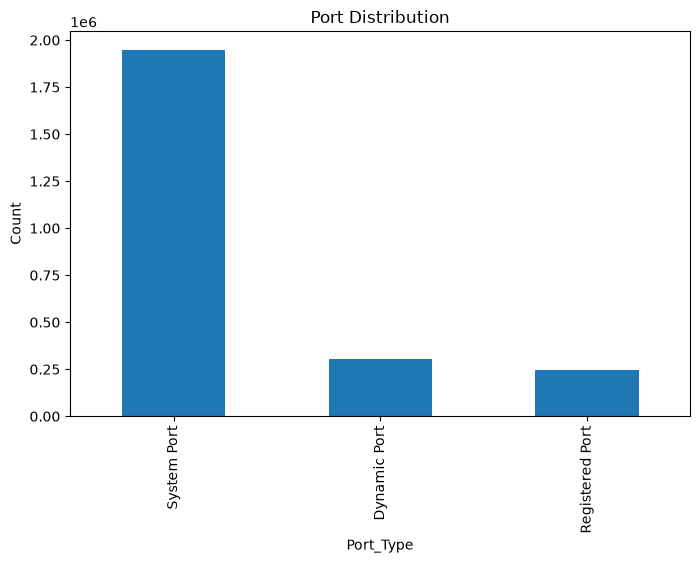

In [30]:
plt.figure(figsize=(8,5))

ds["Port_Type"].value_counts().plot(
    kind="bar"
)

plt.title("Port Distribution")
plt.ylabel("Count")
plt.show()

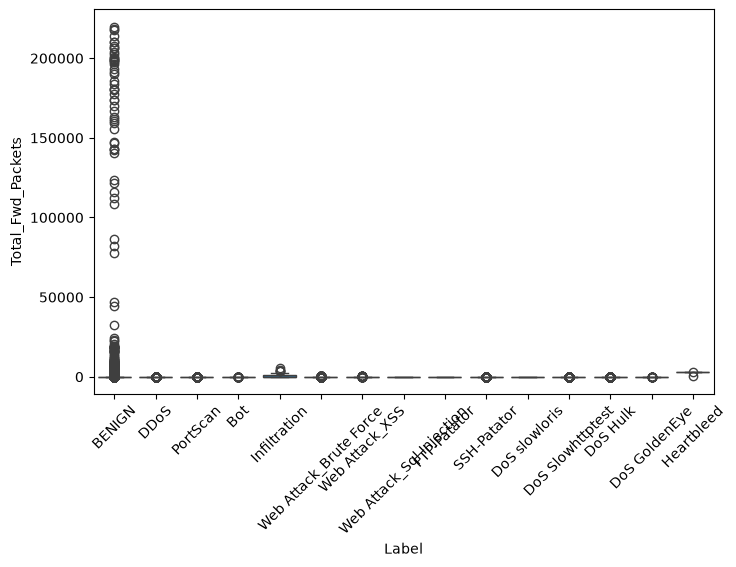

In [31]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=ds,
    x="Label",
    y="Total_Fwd_Packets"
)

plt.xticks(rotation=45)
plt.show()

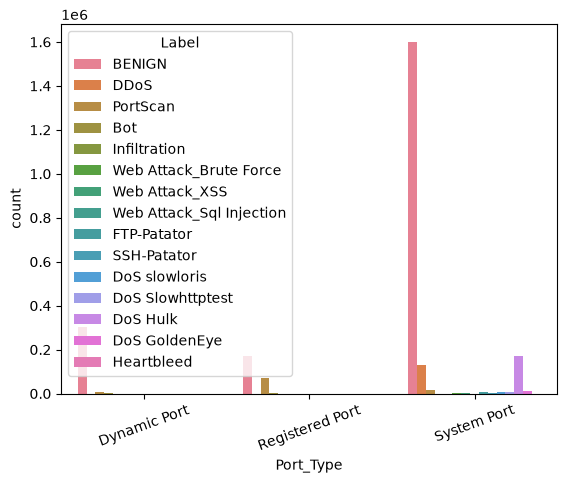

In [32]:
sns.countplot(
    data=ds,
    x="Port_Type",
    hue="Label"
)

plt.xticks(rotation=20)
plt.show()

In [33]:
corr_matrix=standard_data.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [34]:
to_drop = [column for column in upper.columns if any(upper[column] > 0.90)]
print(f"Features to drop ({len(to_drop)}): {to_drop}")

Features to drop (34): ['Fwd_Packet_Length_Max', 'Fwd_Packet_Length_Mean', 'Bwd_Packet_Length_Max', 'Bwd_Packet_Length_Mean', 'Flow_Packets/s', 'Flow_IAT_Mean', 'Flow_IAT_Max', 'Fwd_IAT_Mean', 'Fwd_IAT_Std', 'Fwd_IAT_Max', 'Bwd_IAT_Mean', 'Bwd_IAT_Std', 'Bwd_IAT_Max', 'Fwd_Header_Length', 'Bwd_Header_Length', 'Fwd_Packets/s', 'Min_Packet_Length', 'Max_Packet_Length', 'Packet_Length_Mean', 'Packet_Length_Std', 'Packet_Length_Variance', 'Average_Packet_Size', 'Avg_Fwd_Segment_Size', 'Avg_Bwd_Segment_Size', 'Fwd_Header_Length.1', 'Subflow_Fwd_Packets', 'Subflow_Fwd_Bytes', 'Subflow_Bwd_Packets', 'Subflow_Bwd_Bytes', 'Active_Max', 'Active_Min', 'Idle_Mean', 'Idle_Max', 'Idle_Min']


In [35]:
ds = ds.drop(columns=to_drop)

In [36]:
ds = ds.drop(columns=['Destination_Port','Flow_Duration'])

In [37]:
ds = ds.replace([np.inf, -np.inf], np.nan, inplace=True)
ds.dropna(inplace=True)

In [38]:
X = ds.drop(columns='Label')
y = ds['Label']

In [39]:
X = pd.get_dummies(X, columns=['Port_Type','Duration_Category'], drop_first=True, dtype=float)
X.columns

Index(['Total_Fwd_Packets', 'Total_Backward_Packets',
       'Total_Length_of_Fwd_Packets', 'Total_Length_of_Bwd_Packets',
       'Fwd_Packet_Length_Min', 'Fwd_Packet_Length_Std',
       'Bwd_Packet_Length_Min', 'Bwd_Packet_Length_Std', 'Flow_Bytes/s',
       'Flow_IAT_Std', 'Flow_IAT_Min', 'Fwd_IAT_Total', 'Fwd_IAT_Min',
       'Bwd_IAT_Total', 'Bwd_IAT_Min', 'Bwd_Packets/s', 'PSH_Flag_Count',
       'ACK_Flag_Count', 'URG_Flag_Count', 'Down/Up_Ratio',
       'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'act_data_pkt_fwd',
       'min_seg_size_forward', 'Active_Mean', 'Active_Std', 'Idle_Std',
       'Port_Type_Registered Port', 'Port_Type_System Port',
       'Duration_Category_Medium', 'Duration_Category_Long'],
      dtype='str')

In [40]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)
y_encoded

array([0, 0, 0, ..., 0, 0, 0], shape=(2498796,))

In [41]:
ds['Label'].value_counts()

Label
BENIGN                      2073053
DoS Hulk                     172846
DDoS                         128016
PortScan                      90694
DoS GoldenEye                 10286
FTP-Patator                    5931
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1948
Web Attack_Brute Force         1470
Web Attack_XSS                  652
Infiltration                     36
Web Attack_Sql Injection         21
Heartbleed                       11
Name: count, dtype: int64

In [42]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.25, random_state=42)

In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [50]:
rf = RandomForestClassifier(n_estimators=30, n_jobs=-1, max_depth=15, random_state=42, class_weight='balanced')
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",30
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featu

In [51]:
y_pred = rf.predict(X_test)
accuracy_score(y_test, y_pred)

0.9921850363134885

In [54]:
import joblib
joblib.dump(rf, "models/netsentinal-random_forest.pkl")
joblib.dump(encoder, "models/netsentinal-label_encoder.pkl")
joblib.dump(standard_scaler, "models/netsentinal-standard_scaler.pkl")
joblib.dump(X_train.columns.tolist(), "models/netsentinal-features.pkl")

['models/netsentinal-features.pkl']